# Notebook B: chia dữ liệu, mô hình, câu hỏi thứ ba và giải thích

**Đề tài:** Dự báo mức sẵn sàng ngày kế tiếp từ lifelog Fitbit và nhật ký tập luyện trên PMData với mười mô hình hồi quy và lời giải thích được kiểm tra

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost shap matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 2178 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: time split inside each person (first 70% of days for training, the rest for test)
import duckdb
con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
feat = con.execute("SELECT * FROM feat ORDER BY pid, date").df()
FITBIT = ['steps', 'very_active', 'sedentary', 'rhr', 'sleep_min', 'sleep_eff', 'sleep_7d', 'rhr_dev', 'steps_dev']
WELL = ['fatigue', 'mood', 'readiness', 'sleep_quality', 'soreness', 'stress', 'ready_base', 'ready_dev']
TRAIN_LOG = ['load', 'load_7d', 'load_28d', 'load_ratio']
X_cols = FITBIT + WELL + TRAIN_LOG + ['dow']; NAIVE = 'readiness'
PERSONAL = ['ready_base', 'ready_dev', 'rhr_dev', 'steps_dev']          # the person's own past level and today's gap
feat[X_cols] = feat[X_cols].fillna(feat.groupby('pid')[X_cols].transform('median')).fillna(feat[X_cols].median())
feat['frac'] = feat.groupby('pid').day_no.rank(pct=True)
train = feat[feat.frac <= 0.7]; test = feat[feat.frac > 0.7]
X_tr, y_tr, X_te, y_te = train[X_cols], train.y, test[X_cols], test.y
GROUP = pd.Series(['watch' if c in FITBIT else 'self-report' if c in WELL else 'training log' if c in TRAIN_LOG else 'calendar'
                   for c in X_cols], index=X_cols)
people = sorted(feat.pid.unique()); ALT = train.pid.isin(people[:8]).to_numpy()     # a different half of the people
assert (train.groupby('pid').date.max() < test.groupby('pid').date.min()).all()      # leakage check
print(len(train), len(test), len(X_cols), 'features', feat.pid.nunique(), 'people')

920 404 22 features 16 people


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [ ]:
# Step 6a: one reference and ten regressors from four families, five seeds, same time split
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Ridge':          lambda s: sc(Ridge(alpha=1.0)),
    'Elastic Net':    lambda s: sc(ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsRegressor(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=s),
    'Random Forest':  lambda s: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=s),
    'LightGBM':       lambda s: LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, subsample=0.8,
                                              subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, subsample=0.8,
                                             colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True,
                                                random_state=s)),
}
naive = test[NAIVE]                                     # reference: the value known now is the forecast
rows, fitted = [['Persistence', MAE(y_te, naive), 0, MSE(y_te, naive) ** 0.5, r2_score(y_te, naive), 0]], {}
for name, make in models.items():
    maes, rmses, r2s, secs = [], [], [], []
    for seed in range(5):
        m = make(seed); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = m.predict(X_te); maes.append(MAE(y_te, p)); rmses.append(MSE(y_te, p) ** 0.5); r2s.append(r2_score(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(maes), np.std(maes), np.mean(rmses), np.mean(r2s), np.mean(secs)])
res = pd.DataFrame(rows, columns=['model', 'MAE', 'sd', 'RMSE', 'R2', 'train_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

# Export predictions from the best model (Extra Trees, seed=0) with date column for time-series traceability
et_seed0 = ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(X_tr, y_tr)
pva = test[['pid']].copy(); pva['date'] = test['date'].values
pva['y_true'] = y_te.values; pva['y_pred'] = et_seed0.predict(X_te)
pva['residual'] = pva['y_pred'] - pva['y_true']
pva.to_csv('report/table_pred_vs_actual.csv', index=False)
print('Saved pred_vs_actual with', len(pva), 'rows including date column')

### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

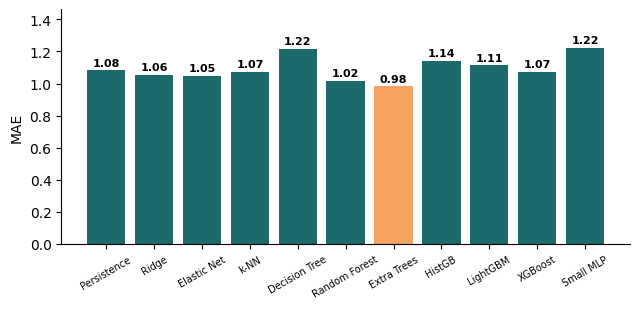

In [ ]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30)
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmin()), fmt='{:.2f}')

## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** chạy các phương pháp giải thích trên mô hình Extra Trees tốt nhất và kiểm chứng chúng theo giao thức của đề tài.
- Deletion: thay thế top-$k$ features ($k \in \{1, \dots, 20\}$) bằng **median** của tập huấn luyện; random deletion trung bình qua 20 Monte Carlo.
- Stability: bootstrap rank stability qua **50 resamples** (Spearman pairwise trung bình).

In [ ]:
# Step 6b: RQ3, which explanation method is faithful and stable, and does the model help a person it has never seen?
import shap
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from sklearn.ensemble import ExtraTreesRegressor
from scipy.stats import spearmanr
def fit_best(X, y, seed=0):
    return ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed).fit(X, y)
def out(m, Z): return m.predict(np.asarray(Z))                         # sklearn predict accepts arrays directly
def pool(sv, cols):                                     # mean absolute attribution per feature, classes pooled
    if isinstance(sv, list): sv = np.stack(sv, axis=-1)                 # older shap returns one array per class
    sv = np.abs(np.asarray(sv)); return sv.mean(axis=0) if sv.ndim == 2 else sv.mean(axis=(0, 2))
def r_tree_shap(m, X, y, n=200): return pool(shap.TreeExplainer(m).shap_values(X.sample(min(n, len(X)), random_state=0)), X.columns)
def r_kernel_shap(m, X, y, n=50):                       # model-agnostic SHAP, 50 background samples
    bg = shap.kmeans(X_tr[X.columns], 50)
    ex = shap.KernelExplainer(lambda Z: out(m, Z), bg)
    return pool(ex.shap_values(X.sample(n, random_state=0), nsamples=300, silent=True), X.columns)
def r_lime(m, X, y, n=50, n_pert=1000):                # LIME procedure (Ribeiro et al., 2016), 1000 perturbations
    rs = np.random.RandomState(0); sd = X_tr[X.columns].std().to_numpy() + 1e-9; w = np.zeros(X.shape[1])
    for x in X.sample(n, random_state=0).to_numpy():
        Z = x + rs.randn(n_pert, len(x)) * sd           # perturb around one row
        p = out(m, Z)
        d = np.sqrt((((Z - x) / sd) ** 2).sum(1)); k = np.exp(-d ** 2 / (0.75 * np.sqrt(len(x))) ** 2)
        w += np.abs(Ridge(alpha=1.0).fit((Z - x) / sd, p, sample_weight=k).coef_)    # weighted local linear surrogate
    return w / n
def r_perm(m, X, y, n=3000):                            # loss of score when one feature is shuffled
    Xv = X.sample(min(n, len(X)), random_state=0)
    return permutation_importance(m, Xv, y.loc[Xv.index], n_repeats=3, scoring='neg_mean_absolute_error', random_state=0).importances_mean
def r_gain(m, X, y): return m.feature_importances_      # impurity-based feature importance (Tree Gain equivalent)
METHODS = {'TreeSHAP': r_tree_shap, 'KernelSHAP': r_kernel_shap, 'LIME': r_lime, 'Permutation': r_perm, 'Tree Gain': r_gain}
def explain_all(m, cols):                               # one ranking per method plus the time each one takes
    R, secs = {}, {}
    for name, f in METHODS.items():
        t0 = time.perf_counter(); R[name] = pd.Series(f(m, X_te[cols], y_te), index=cols).sort_values(ascending=False)
        secs[name] = time.perf_counter() - t0
    return R, secs
def score(m, X): return MAE(y_te, m.predict(X))
best = fit_best(X_tr, y_tr); base = score(best, X_te); ranks, secs = explain_all(best, X_cols)
# (1) faithfulness by deletion: neutralise the k top-ranked features (training-set median) and score again
#     k in {1, ..., 20} as described in the paper; random deletion averaged over 20 Monte Carlo shuffles
KS = list(range(1, min(21, len(X_cols)))); medians = X_tr[X_cols].median(); curve = {}
for name, r in ranks.items():
    if name == 'Random': continue
    curve[name] = []
    for k in KS:
        Xp = X_te.copy(); Xp[r.index[:k]] = medians[r.index[:k]].values; curve[name].append(score(best, Xp))
# random deletion: average over 20 Monte Carlo shuffles per k
rand_curve = []
for k in KS:
    mc = []
    for mc_seed in range(20):
        perm = np.random.RandomState(mc_seed).permutation(X_cols)
        Xp = X_te.copy(); Xp[perm[:k]] = medians[perm[:k]].values; mc.append(score(best, Xp))
    rand_curve.append(np.mean(mc))
curve['Random'] = rand_curve
curve = pd.DataFrame(curve, index=KS); curve.to_csv('report/table_rq3_deletion_curve.csv')
# (2) stability: bootstrap rank stability across 50 resamples
stab = {name: [] for name in METHODS}
for b in range(50):
    idx = np.random.RandomState(b).choice(len(X_tr), len(X_tr), replace=True)
    Xb, yb = X_tr.iloc[idx], y_tr.iloc[idx]
    mb = fit_best(Xb, yb, seed=b)
    rb, _ = explain_all(mb, X_cols)
    for name in METHODS:
        stab[name].append(rb[name][X_cols].values)
stability = {}
for name in METHODS:
    pairs = []
    for i in range(len(stab[name])):
        for j in range(i + 1, len(stab[name])):
            pairs.append(spearmanr(stab[name][i], stab[name][j])[0])
    stability[name] = np.mean(pairs)
tab = pd.DataFrame({'MAE_after_top5': curve.loc[5], 'deletion_area': curve.mean(),      # higher area = more faithful
                    'rank_stability': stability,
                    'seconds': secs})
tab.to_csv('report/table_rq3_methods.csv'); print('MAE before deletion', round(base, 3)); print(tab.round(3))
# (3) a person the model has never seen: leave one person out, raw features against personal-baseline features
RAW = [c for c in X_cols if c not in PERSONAL]; lopo = []
for p in people:
    tr, te = feat[feat.pid != p], feat[feat.pid == p]; row = {'pid': p, 'n': len(te), 'MAE_same_as_today': MAE(te.y, te.readiness)}
    for tag, cols in [('raw', RAW), ('personal', X_cols)]:
        row['MAE_' + tag] = MAE(te.y, fit_best(tr[cols], tr.y).predict(te[cols]))
    lopo.append(row)
lopo = pd.DataFrame(lopo); lopo.to_csv('report/table_rq3_lopo.csv', index=False)
print('unseen person, mean MAE raw', round(lopo.MAE_raw.mean(), 3), 'personal', round(lopo.MAE_personal.mean(), 3),
      'people helped', int((lopo.MAE_personal < lopo.MAE_raw).sum()), 'of', len(lopo))

## Bước 6c. Đối chiếu và bảng tham số

- **Làm gì:** đặt kết quả các phương pháp cạnh nhau, lưu hình SHAP và tham số mô hình.
- **Vì sao:** bảng tham số và danh sách đặc trưng đứng đầu đi vào phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [ ]:
# Step 6c: what the methods say side by side, and the selected parameter table
import json, matplotlib.pyplot as plt
top = pd.DataFrame({k: r.index[:10] for k, r in ranks.items() if k != 'Random'})
top.to_csv('report/table_top10_by_method.csv', index=False); print(top.head(5))
votes = pd.Series([f for k, r in ranks.items() if k != 'Random' for f in r.index[:5]]).value_counts()
votes.rename('methods_listing_in_top5').to_csv('report/table_consensus_features.csv'); print(votes.head(8))
grp = pd.DataFrame({k: (r.clip(lower=0) / r.clip(lower=0).sum()).groupby(GROUP).sum() for k, r in ranks.items() if k != 'Random'})
grp.to_csv('report/table_group_share.csv'); print(grp.round(3))         # do the methods blame the same feature group?
Xs = X_te.sample(min(500, len(X_te)), random_state=0)
shap.summary_plot(shap.TreeExplainer(best).shap_values(Xs), Xs, show=False, plot_type='bar')
plt.savefig('report/fig_shap.png', dpi=300, bbox_inches='tight'); plt.close()
json.dump(best.get_params(), open('report/params_best.json', 'w'), indent=2, default=str)   # parameter table

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [ ]:
import glob
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 1, 'RQ3 tables missing'
assert res.iloc[1:, 1].min() <= res.iloc[0, 1], 'no model beats the persistence reference: check features and split'
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_rq1.png', 'fig_rq2_models.png', 'fig_shap.png', 'params_best.json', 'table_cleaning_log.csv', 'table_consensus_features.csv', 'table_group_share.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_rq2.csv', 'table_rq3_deletion_curve.csv', 'table_rq3_lopo.csv', 'table_rq3_methods.csv', 'table_top10_by_method.csv']
Notebook B: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: